In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
import torch
from torchvision import datasets, transforms
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
import numpy as np


In [ ]:
from torch.utils.data import DataLoader
transform = transforms.ToTensor()
train_data = datasets.FashionMNIST(
    root='./data',
    train=True,
    transform=transform,
    download=True
)
test_data = datasets.FashionMNIST(
    root='./data',
    train=False,
    transform=transform,
    download=True
)
print(len(train_data))
print(len(test_data))

100%|██████████| 26.4M/26.4M [00:02<00:00, 13.0MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 201kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.78MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 16.9MB/s]

60000
10000


In [ ]:
torch.manual_seed(42)

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f'using device:{device}')

using device:cuda


In [ ]:
train_loader = DataLoader(
    train_data,
    batch_size=32,
    shuffle=True
)

test_loader = DataLoader(
    test_data,
    batch_size=32,
    shuffle=False
)

In [ ]:
images, labels = next(iter(train_loader))

print(images.shape)
print(labels.shape)

torch.Size([32, 1, 28, 28])
torch.Size([32])


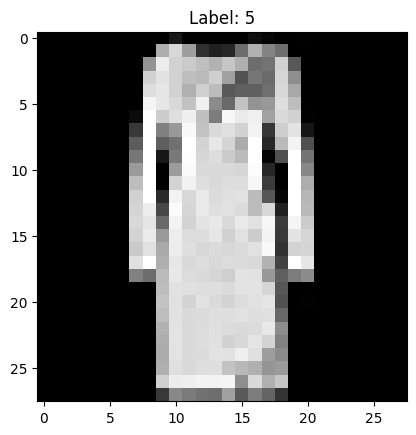

In [ ]:
import matplotlib.pyplot as plt

plt.imshow(images[8].squeeze(), cmap='gray')
plt.title(f"Label: {labels[0].item()}")
plt.show()

In [ ]:
from torch.autograd import forward_ad
class myNN(nn.Module):
  def __init__(self, input_dim, output_dim, num_hidden_layers, neurons_per_layers, dropout_rate):
    super().__init__()
    layers = []

    # First layer maps from input_dim to neurons_per_layers
    current_input_dim = input_dim

    for i in range(num_hidden_layers):
      layers.append(nn.Linear(current_input_dim, neurons_per_layers))
      layers.append(nn.BatchNorm1d(neurons_per_layers))
      layers.append(nn.ReLU())
      layers.append(nn.Dropout(dropout_rate))
      # Subsequent hidden layers will map from neurons_per_layers to neurons_per_layers
      current_input_dim = neurons_per_layers

    layers.append(nn.Linear(neurons_per_layers, output_dim))
    self.model = nn.Sequential(*layers)

  def forward(self, x):
    return self.model(x)

In [ ]:
from torch.optim import optimizer
def objective(trail):
  num_hidden_layers = trail.suggest_int('num_hidden_layers', 1, 5)
  neurons_per_layers = trail.suggest_int('neurons_per_layers', 8, 128, log=True)
  epochs = trail.suggest_int('epochs', 10, 100, step=10)
  learning_rate = trail.suggest_float('learning_rate', 1e-5, 1e-1, log=True)
  dropout_rate = trail.suggest_float('dropout_rate', 0.1, 0.5, step=0.1)
  batch_size = trail.suggest_categorical('batch_size', [16, 32, 64, 256])
  optimizer_name = trail.suggest_categorical('optimizer', ['adam', 'sgd'])
  weight_decay = trail.suggest_float('weight_decay', 1e-5, 1e-1, log=True)

  train_loader = DataLoader(
    train_data,
    batch_size=batch_size,
    shuffle=True
  )
  test_loader = DataLoader(
    test_data,
    batch_size=batch_size,
    shuffle=False
  )

  input_dim = 784
  output_dim = 10
  model = myNN(input_dim, output_dim, num_hidden_layers, neurons_per_layers, dropout_rate).to(device)
  criterion = nn.CrossEntropyLoss()

  if optimizer_name == 'adam':
    opt = optim.Adam(model.parameters(), lr=learning_rate, weight_decay=weight_decay)
  else:
    opt = optim.SGD(model.parameters(), lr=learning_rate, weight_decay=weight_decay)

  for epoch in range(epochs):
    model.train()
    for images, labels in train_loader:
      images = images.view(images.shape[0], -1).to(device)
      labels = labels.to(device)
      outputs = model(images)
      loss = criterion(outputs, labels)
      opt.zero_grad()
      loss.backward()
      opt.step()

    model.eval()
    total = 0
    correct = 0
    with torch.no_grad():
      for images, labels in test_loader:
        images = images.view(images.shape[0], -1).to(device)
        labels = labels.to(device)
        outputs = model(images)
        _, predicted = torch.max(outputs.data, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    accuracy = 100 * correct / total
    trail.report(accuracy, epoch)

  return accuracy

In [ ]:
!pip install optuna

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [optuna]


In [ ]:
import optuna

study = optuna.create_study(direction='maximize')

[I 2026-11-17 15:19:35,925] A new study created in memory with name: no-name-585c3ecf-ece9-46d3-b123-5a2079be69f6


In [ ]:
study.optimize(objective, n_trials=10)

[I 2026-11-17 15:39:26,434] Trial 2 finished with value: 84.39 and parameters: {'num_hidden_layers': 4, 'neurons_per_layers': 90, 'epochs': 60, 'learning_rate': 0.004440224370601946, 'dropout_rate': 0.30000000000000004, 'batch_size': 256, 'optimizer': 'adam', 'weight_decay': 0.0009402668424496361}. Best is trial 2 with value: 84.39.
[I 2026-11-17 16:00:27,895] Trial 3 finished with value: 64.55 and parameters: {'num_hidden_layers': 5, 'neurons_per_layers': 17, 'epochs': 60, 'learning_rate': 0.00550826511441215, 'dropout_rate': 0.1, 'batch_size': 16, 'optimizer': 'sgd', 'weight_decay': 0.09212363648145144}. Best is trial 2 with value: 84.39.
[I 2026-11-17 16:13:38,343] Trial 4 finished with value: 82.7 and parameters: {'num_hidden_layers': 3, 'neurons_per_layers': 109, 'epochs': 100, 'learning_rate': 0.0333246427025909, 'dropout_rate': 0.30000000000000004, 'batch_size': 256, 'optimizer': 'adam', 'weight_decay': 3.818628847205132e-05}. Best is trial 2 with value: 84.39.
[I 2026-11-17 16: